# **Multi-Building Design Update of two Spring-Mass Systems**

This Jupyter Notebook demonstrates how to use the joint **Multi-Model Update** with the example of two, previously trained 1D Spring-Mass Hybrid Models (see the notebook on Hybrid Digital Twinning [here](https://buildchain.ilab.sztaki.hu/notebooks/1_hybrid_digital_twinning/hybrid_toy_1timestep.html)).

The main objective of the Multi-Building Updating is to calibrate uncertain parameters of simulation models across multiple buildings or experimental setups using shared measurement data. This ensemble-based calibration improves generalizability and robustness compared to single-structure updates.

### **System Overview**  
Both spring-mass systems follow Hooke’s Law and Newton’s Second Law:  

$$
F = -k x
$$

where:  
- \( k \) is the **spring stiffness**,  
- \( x \) is the **displacement from equilibrium**,  
- \( m \) is the **mass of the attached object**.  

### **Analytical Solution**  
For an ideal undamped system, the displacement at a given time step is given by:  

$$
u(T) = u_0 \cos \left( \sqrt{\frac{k}{m}} T \right) + \frac{v_0}{\sqrt{\frac{k}{m}}} \sin \left( \sqrt{\frac{k}{m}} T \right)
$$

where:  
- \( u_0 \) is the **initial displacement**,  
- \( v_0 \) is the **initial velocity**,  
- \( k \) and \( m \) can change dynamically in the twinning process,  
- **\( T = 10 \) is the single time step at which the system is evaluated**.

## Imports

In [1]:
import sys
import os
parent_dir = os.path.abspath("../../libraries/surrogate_modelling")
sys.path.insert(0, parent_dir)

In [2]:
import pickle
import pandas as pd
import utils
from multibuilding_update import JointManager

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

## Load models

In this example we simply load two previusly trained hybrid models of the two system. The chosen parameters of the models were:

- \( m1 and m2 \) **mass of the attached object** and
- \( k1 and k2 \) **spring stiffness**.

The models are connected through their **m** parameter. All parameters are defined with uniform distributions, both **m1** and **m2** between bounds [0.5, 2.5], while **k1** and **k2** between [1.73, 2.11] and [1.52, 2.0]

In [3]:
#Load measurement data
z_spring1 = pd.read_csv('../data/spring_data/z_spring1_df.csv')
z_spring2 = pd.read_csv('../data/spring_data/z_spring2_df.csv')

#Load standard deviation of the measurement error
sigma_spring1 = pd.read_csv('../data/spring_data/sigma_spring1.csv')
sigma_spring2 = pd.read_csv('../data/spring_data/sigma_spring2.csv')

#Load surrogate models
with open('../data/spring_data/Spring1_model.sm', 'rb') as file:
    Spring1_model = pickle.load(file)
with open('../data/spring_data/Spring2_model.sm', 'rb') as file:
    Spring2_model = pickle.load(file)

# Update

In [4]:
#Define joint parameters
joint_parameters = {'m': ['m1', 'm2']}

#Define the joint manager
j = JointManager([Spring1_model, Spring2_model], joint_parameters)
print(j.Q.params)

{'m': U(0, 1), 'k1': U(1.73, 2.11), 'k2': U(1.52, 2.0)}


In [5]:
#Update inputs
nwalkers=32
niter=20
nburn=100

#Update
j.update([z_spring1, z_spring2], [sigma_spring1, sigma_spring2], nwalkers=nwalkers, niter=niter, nburn=nburn)

MCMC creating
Burning period


  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [00:03<00:00, 29.32it/s]


MCMC running


100%|██████████| 20/20 [00:00<00:00, 32.59it/s]

--- 4.044522762298584 seconds ---


# Results

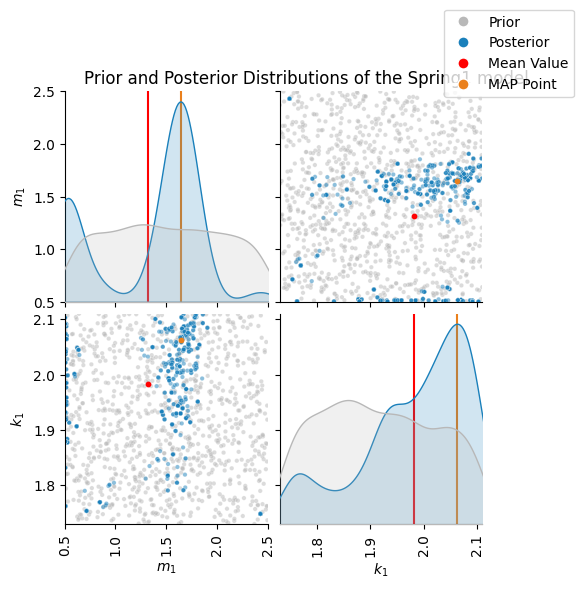

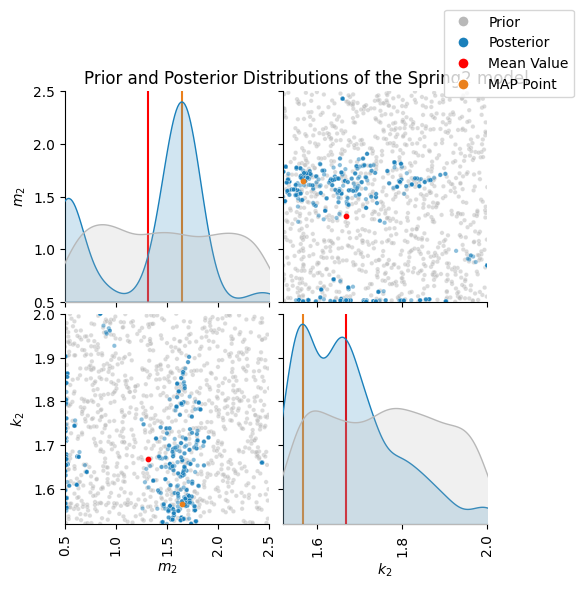

In [6]:
# Plot the MCMC sampling results along with the mean and MAP points for each model
figs = utils.plot_multibuilding_MCMC(j, map_point=True, model_names=['Spring1', 'Spring2'], formatted_param_names=[["$m_{1}$", "$k_{1}$"], ["$m_{2}$", "$k_{2}$"]])

In [7]:
model_index = 0
map_point, mean, variance, posterior_samples = j.get_data_of_model(model_index)

In [8]:
map_point

,m1,k1
0,1.645074,2.062218


In [9]:
mean

,m1,k1
0,1.318539,1.982745


In [10]:
variance

,m1,k1
0,0.141935,0.009994


In [11]:
posterior_samples

,m1,k1
0,1.766405,2.080112
1,0.506722,2.036962
2,0.846091,1.769789
3,0.514124,2.009457
4,0.514146,1.984937
...,...,...
635,0.697099,1.790244
636,1.710198,1.943099
637,1.599215,2.058771
638,1.669708,1.791417
